# Gas disc ICs on top of a GalIC galaxy

The workflow this package is built for: a collisionless galaxy (dark halo, bulge, stellar disc) already exists, typically
from [GalIC](https://www.h-its.org/2014/11/05/galic-code/), and a **gas disc** is added in the *analytic* potential of those
components. This notebook walks through it step by step, with checks at each stage. Every step has a command-line
equivalent that uses the same parameter file (`galic_m1.toml`), so what you tune here can be run in batch:

| step | here | command line |
|---|---|---|
| 1. model, rotation curve, vertical resolution | `workflow.model_report` | `galaxy-components check galic_m1.toml` |
| 2. does the snapshot match the analytic model? | `workflow.compare_snapshot` | printed by `add-gas` (`--strict` makes a mismatch an error) |
| 3. sample the gas disc | `gas_disc.sample_particles` | `galaxy-components disc galic_m1.toml` (gas only) |
| 4. add it to the snapshot, write the IC file | `workflow.add_gas_to_snapshot` | `galaxy-components add-gas galic_m1.toml --snapshot galic.hdf5 --out ic.hdf5` |

`./build.sh GALIC_SNAPSHOT.hdf5` runs steps 1, 2 and 4 in one go. Units are kpc, km/s and 1e10 Msol.

In [1]:
import sys
from pathlib import Path

try:
    import galaxy_components
except ImportError:                       # running from a checkout without installing it
    sys.path.insert(0, str(Path("../..").resolve()))

import warnings
import numpy as np
import matplotlib.pyplot as plt

from galaxy_components import gas_disc, workflow
from galaxy_components.params import read_params
from galaxy_components.system import read_system

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

# ---- settings ---------------------------------------------------------------------------------
PARAMS = "galic_m1.toml"          # the analytic model: the same file the command-line steps use
GALIC_SNAPSHOT = None             # path to your GalIC HDF5 snapshot; None writes a stand-in so this runs anywhere
OUT = "ic_with_gas.hdf5"
NDISC = 100_000                   # gas particles (the parameter file has 200k)
SEED = 19721
BACKGROUND_GRID = False           # True: convert the gas to an AREPO background-grid mesh

## 1. The analytic model

`galic_m1.toml` describes GalIC "Model-M1" (V200 = 200 km/s, c = 10, MD = 0.035, MB = 0.05, DiskHeight = 0.2) plus a gas disc
of 25 % of the stellar mass. Two things matter for the gas disc's equilibrium:

* the **halo, bulge and stellar disc** are the same analytic profiles GalIC used (Hernquist halo with $M_{200}$ the Hernquist
  *total* mass, as in GalIC), and
* the stellar disc has the **right thickness** (`zdisc` = GalIC `DiskHeight`). A razor-thin stellar disc makes the gas disc
  up to ~6× too thin near R_d (and still ~2× at 3 R_d).

Replace `fdisc` in the parameter file by the scale length your GalIC run reports.

In [2]:
p = read_params(PARAMS)
p.ndisc = NDISC
rep = workflow.model_report(p)
print(rep.format())

M200 = 186.1 (1e10 Msol), R200 = 200.0 kpc, halo scale a = 34.52 kpc
stars: disc 6.514 (R_d = 4.42 kpc, z0/R_d = 0.2), bulge 9.306; gas disc 1.63 (0.25 of the stellar disc), cs = 9.09 km/s
ndisc = 100,000 (sobol), particle mass 1.630e-05 (1e10 Msol)

   R/R_d   R [kpc]   vc_bg   vc_gas   vrot   [km/s]   gas half-mass height [pc]   h/H
     0.5      2.14   212.7    45.6   217.4                27.2                 5.3  <-- unresolved
     1.0      4.29   252.4    65.5   260.5                41.4                 4.7  <-- unresolved
     2.0      8.59   281.6    78.0   291.8                81.3                 4.2  <-- unresolved
     3.0     13.66   287.3    74.9   296.2               156.8                 4.0  <-- unresolved
     5.0     21.72   280.4    62.2   286.2               354.2                 4.2  <-- unresolved
     8.0     34.53   266.5    47.3   269.2               756.2                 6.7  <-- unresolved

Vertical resolution: h/H > 2 for 100% of the gas mass; ndisc ~ 1,891

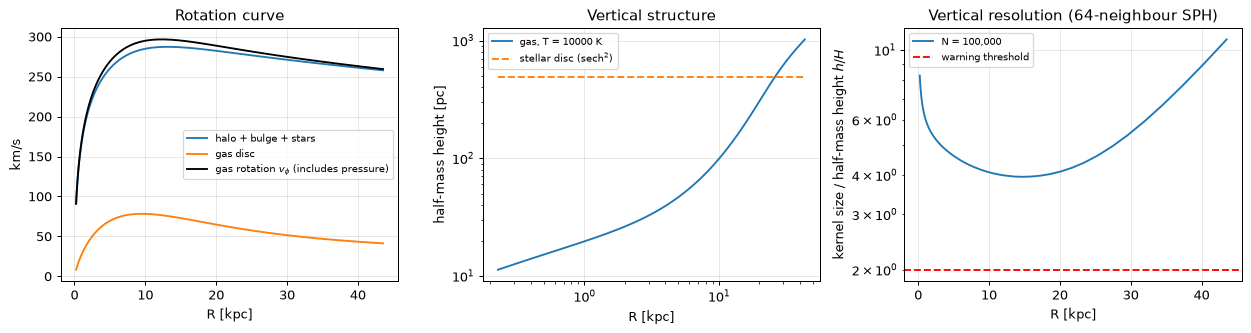

In [3]:
model, disc = rep.model, rep.disc
rd = model.rdisc
R = disc.rtab
sel = (R > 0.05 * rd) & (R < 10 * rd)
Hz = np.array([np.interp(0.5, mz, disc.ztab) for mz in disc.mztab])      # gas half-mass height
res = gas_disc.resolution(disc, rep.mpart)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(R[sel], np.sqrt(disc.vcomp["background"][sel]), label="halo + bulge + stars")
ax[0].plot(R[sel], np.sqrt(disc.vcomp["gas"][sel]), label="gas disc")
ax[0].plot(R[sel], disc.vrot[sel], "k", label="gas rotation $v_\\phi$ (includes pressure)")
ax[0].set(xlabel="R [kpc]", ylabel="km/s", title="Rotation curve"); ax[0].legend(fontsize=8)

ax[1].loglog(R[sel], 1e3 * Hz[sel], label="gas, T = %g K" % p.temp)
ax[1].loglog(R[sel], 1e3 * 0.549 * p.zdisc * rd * np.ones(sel.sum()), "--", label="stellar disc (sech$^2$)")
ax[1].set(xlabel="R [kpc]", ylabel="half-mass height [pc]", title="Vertical structure"); ax[1].legend(fontsize=8)

ax[2].semilogy(R[sel], res["ratio"][sel], label="N = %s" % f"{p.ndisc:,}")
ax[2].axhline(gas_disc.HRES_MAX, color="r", ls="--", label="warning threshold")
ax[2].set(xlabel="R [kpc]", ylabel="kernel size / half-mass height $h/H$", title="Vertical resolution (64-neighbour SPH)")
ax[2].legend(fontsize=8)
plt.tight_layout()

## 2. How many gas particles?

The vertical structure is solved in the continuum limit. A particle code reproduces it only if the kernel (SPH, 64 neighbours)
or mesh cell is small compared with the half-mass height $H$. When $h/H$ is large the midplane density is smoothed away, the
pressure force falls short of gravity, and the disc collapses and rebounds: the "ringing". In a periodic-patch SPH test the
collapse of $H$ was ~0 at $h/H=1$, ~7 % at 2 and ~19 % at 4. Since $h\propto N^{-1/3}$, resolving a thin, cold disc is expensive.

1,891,437 particles resolve 90% of the gas at T = 10000 K


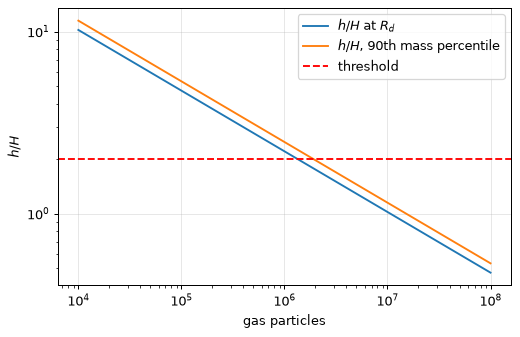

In [4]:
r0, rcut, m0, mkeep = gas_disc.disc_window(p, disc)
Ns = np.logspace(4, 8, 17)
rows = [gas_disc.resolution_summary(disc, (mkeep - m0) / n, n, r0, rcut) for n in Ns]

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(Ns, [r["ratio_rd"] for r in rows], label="$h/H$ at $R_d$")
ax.loglog(Ns, [r["q90"] for r in rows], label="$h/H$, 90th mass percentile")
ax.axhline(gas_disc.HRES_MAX, color="r", ls="--", label="threshold")
ax.set(xlabel="gas particles", ylabel="$h/H$"); ax.legend()
print(f"{rows[0]['n90']:,} particles resolve 90% of the gas at T = {p.temp:g} K")

A thicker disc needs far fewer particles. The temperature of the IC sets the gas thickness, so a warmer start that cools once the
run begins is the usual compromise:

In [5]:
for T in (1e4, 3e4, 1e5):
    q = read_params(PARAMS); q.ndisc = NDISC; q.temp = T
    r = workflow.model_report(q).summary
    print(f"T = {T:8.0e} K: h/H at R_d = {r['ratio_rd']:4.1f}, 90th percentile {r['q90']:4.1f}, "
          f"N for 90% resolved = {r['n90']:>11,}")

T =    1e+04 K: h/H at R_d =  4.7, 90th percentile  5.3, N for 90% resolved =   1,891,437


T =    3e+04 K: h/H at R_d =  2.1, 90th percentile  2.4, N for 90% resolved =     172,864


T =    1e+05 K: h/H at R_d =  1.3, 90th percentile  1.5, N for 90% resolved =      40,572


## 3. Sample the gas disc

`sampling = "sobol"` places particles quasi-randomly (a scrambled Sobol' sequence in mass inside R, vertical quantile and
azimuth): the same distribution as Poisson sampling with about 3× less shot noise in the density an SPH or mesh code estimates.
It does not remove the smoothing bias of section 2.

Disc mass to R=111.071 kpc: 1.63025; particle mass 1.6302e-05
100,000 particles of mass 1.630e-05; rotation speed at R_d = 262.2 km/s


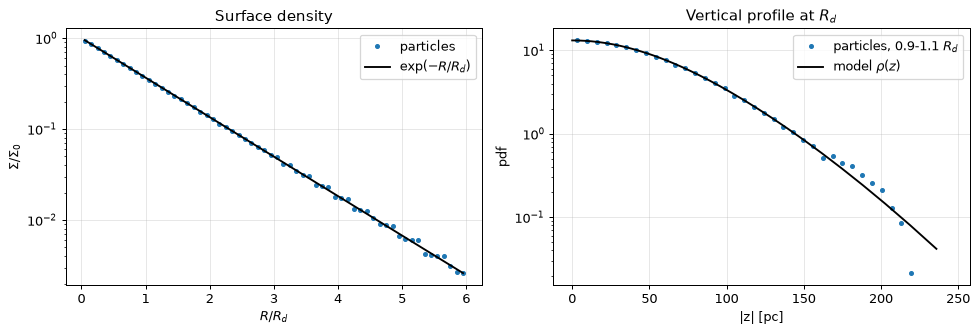

In [6]:
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    pos, vel, ug, mpart = gas_disc.sample_particles(p, disc, p.ndisc, np.random.default_rng(SEED))
for x in w:
    print("WARNING:", x.message)

Rp = np.hypot(pos[:, 0], pos[:, 1])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.linspace(0, 6 * rd, 61)
h, e = np.histogram(Rp, bins)
mid = 0.5 * (e[1:] + e[:-1])
ax[0].semilogy(mid / rd, h / (2 * np.pi * mid * np.diff(e)) * mpart / disc.sigma0, "o", ms=3, label="particles")
ax[0].semilogy(mid / rd, np.exp(-mid / rd), "k", label="exp($-R/R_d$)")
ax[0].set(xlabel="$R/R_d$", ylabel="$\\Sigma/\\Sigma_0$", title="Surface density"); ax[0].legend()

k = int(np.argmin(abs(disc.rtab - rd)))
s = (Rp > 0.9 * rd) & (Rp < 1.1 * rd)
za = np.abs(pos[s, 2])
zb = np.linspace(0, 6 * Hz[k], 40)
hz, ez = np.histogram(za, zb, density=True)
rho = 10 ** disc.lrho[k]
ax[1].semilogy(0.5 * (ez[1:] + ez[:-1]) * 1e3, hz, "o", ms=3, label="particles, 0.9-1.1 $R_d$")
zz = disc.ztab[disc.ztab < zb[-1]]
ax[1].semilogy(zz * 1e3, np.interp(zz, disc.ztab, rho) / np.trapezoid(rho, disc.ztab), "k", label="model $\\rho(z)$")
ax[1].set(xlabel="|z| [pc]", ylabel="pdf", title="Vertical profile at $R_d$"); ax[1].legend()
plt.tight_layout()
print(f"{len(pos):,} particles of mass {mpart:.3e}; rotation speed at R_d = {np.interp(rd, disc.rtab, disc.vrot):.1f} km/s")

## 4. Does the snapshot match the model?

The gas disc is in equilibrium in *the analytic model's* potential. If the snapshot's halo, bulge or stellar disc differ from
it, so will the gas disc's balance. `compare_snapshot` checks the masses, the stellar disc's scale length and thickness (from the
particle distribution), its spin direction and its centre.

Set `GALIC_SNAPSHOT` above to use your own file. By default a **stand-in** is written: a spherical Hernquist halo and bulge plus
an exponential/sech² disc with the model's own parameters. It is only there to exercise the pipeline; it is not an equilibrium model.

In [7]:
if GALIC_SNAPSHOT is None:
    GALIC_SNAPSHOT = workflow.standin_snapshot(p, "standin_snapshot.hdf5")
    print("using a stand-in snapshot (not an equilibrium model):", GALIC_SNAPSHOT)
snap = read_system(GALIC_SNAPSHOT, "snapshot")
print({t: len(s["pos"]) for t, s in snap.species.items()})
print()
for f in workflow.compare_snapshot(p, model, snap.species):
    print(f.format())

using a stand-in snapshot (not an equilibrium model): standin_snapshot.hdf5
{1: 40000, 2: 20000, 3: 8000}

ok    halo mass [1e10 Msol]        snapshot      170.3   model      170.3   (GalIC: M200 - bulge - stellar disc)
ok    bulge mass [1e10 Msol]       snapshot      9.306   model      9.306   
ok    stellar disc mass [1e10 Msol] snapshot      6.514   model      6.514   
ok    disc scale length [kpc]      snapshot      4.435   model      4.422   (mean R / 2)
ok    disc thickness z0 [kpc]      snapshot     0.8732   model     0.8844   (median |z| / 0.549; sech^2)
ok    disc spin direction (Lz > 0) snapshot  1.597e+04   model          1   gas rotates counter-clockwise about +z
ok    stellar-disc centre offset [kpc] snapshot     0.1369   model          0   the gas disc is centred on the origin


## 5. Add the gas disc and write the IC file

`add_gas_to_snapshot` samples the gas disc (same seed as above, so the same particles), puts it at the origin with the snapshot's
particles, and writes one GADGET HDF5 file. With `BACKGROUND_GRID = True` the gas is converted to an AREPO background-grid mesh.
`strict=True` turns any failed check from section 4 into an error.

In [8]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    out = workflow.add_gas_to_snapshot(p, GALIC_SNAPSHOT, OUT, seed=SEED, background_grid=BACKGROUND_GRID, verbose=False)
ic = read_system(OUT, "ic")
print("wrote", OUT)
for t, s in sorted(ic.species.items()):
    print(f"  PartType{t}: {len(s['pos']):>8,} particles, mass {ic.mass(t):10.4g} (1e10 Msol)")

Disc mass to R=111.071 kpc: 1.63025; particle mass 1.6302e-05
wrote ic_with_gas.hdf5
  PartType0:  100,000 particles, mass       1.63 (1e10 Msol)
  PartType1:   40,000 particles, mass      170.3 (1e10 Msol)
  PartType2:   20,000 particles, mass      6.514 (1e10 Msol)
  PartType3:    8,000 particles, mass      9.306 (1e10 Msol)


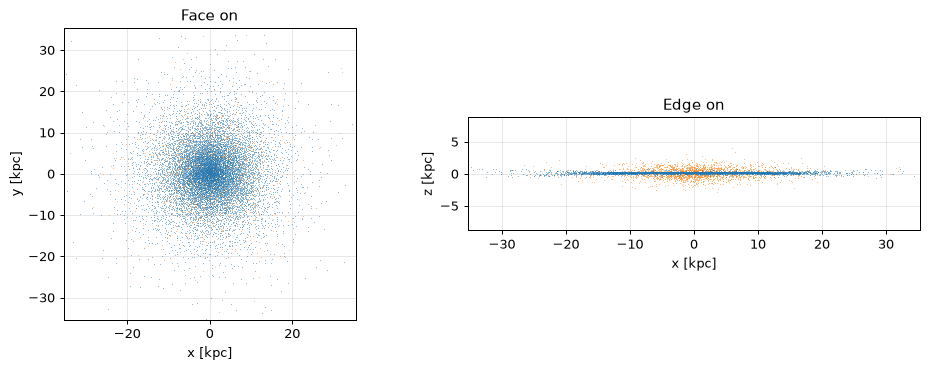

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
gas, stars = ic.species[0]["pos"], ic.species[2]["pos"]
ax[0].plot(stars[::10, 0], stars[::10, 1], ",", color="C1", alpha=0.5, label="stellar disc")
ax[0].plot(gas[::10, 0], gas[::10, 1], ",", color="C0", alpha=0.5, label="gas disc")
ax[0].set(xlim=(-8 * rd, 8 * rd), ylim=(-8 * rd, 8 * rd), aspect="equal", xlabel="x [kpc]", ylabel="y [kpc]", title="Face on")
ax[1].plot(stars[::10, 0], stars[::10, 2], ",", color="C1", alpha=0.5)
ax[1].plot(gas[::10, 0], gas[::10, 2], ",", color="C0", alpha=0.5)
ax[1].set(xlim=(-8 * rd, 8 * rd), ylim=(-2 * rd, 2 * rd), aspect="equal", xlabel="x [kpc]", ylabel="z [kpc]", title="Edge on")
plt.tight_layout()

## Run it from the command line

```bash
galaxy-components check   galic_m1.toml                    # step 1 (add --ndisc N to assess another particle number)
galaxy-components add-gas galic_m1.toml --snapshot galic.hdf5 --out ic.hdf5 --strict
./build.sh galic.hdf5 ic.hdf5                              # both, in one go
```

## Notes

* **Gas on top of GalIC.** GalIC's halo has $M_{200}-M_{\rm bulge}-M_{\rm disc}$ with $M_{\rm disc}$ the *stellar* disc. Here the
  gas disc is also taken out of $M_{200}$, so the model halo is lighter than GalIC's by the gas mass (about 1 % for this model; the
  report in section 1 prints it).
* **Scale length.** `fdisc` is the stellar disc scale length over the Hernquist scale $a$. Use the value GalIC reports, not the
  Mo-Mao-White estimate in the parameter file.
* **Equilibrium holds only in the analytic potential.** The gas does not feel the disc's response in the N-body halo; for a
  heavy disc, run GalIC with the disc included (it does) and keep the gas mass modest.
* The gas halo and an N-body halo can also be built (`galaxy-components galaxy`), but this workflow does not use them.